# General Tasks — Group 19

**Members:** Enise Irem Colak, Alexander Christian Fridrich, Patrick Paul Tobias Kahl, Eya Rebai, Lela Tvaliashvili

**Table of contents**

1. [Exercise 1 — Logistics delay of component K7 (8 points)](#task1)
2. [Exercise 2 — Why data is stored in separate files (2 points)](#task2)
3. [Exercise 3 — Parts T16 in vehicles registered in Adelshofen (3 points)](#task3)
4. [Exercise 4 — Attributes of the registration table (2 points)](#task4)
5. [Exercise 5 — Linear model for mileage (5 points)](#task5)
6. [Exercise 6 — Hit-and-run investigation (5 points)](#task6)

**Task interpretation**
- `Produktionsdatum` comes from `Komponente_K7.csv`.
- `Wareneingang` comes from `Logistikverzug_K7.csv`.
- Goods are assumed to be **issued one calendar day after production**.
- The newly created analysis table is exported as `Logistics_delay.csv`.
- For working-day calculations, Saturday and Sunday are excluded. Public holidays are **not** excluded because no holiday calendar is supplied.

The two source CSV files use different delimiters, so the import function below detects the delimiter automatically.

In [1]:
# Core imports used throughout the notebook.
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
from scipy import stats

import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.io as pio

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import confusion_matrix, classification_report, balanced_accuracy_score

import matplotlib.pyplot as plt

# Show Plotly charts inline in a Jupyter Notebook.
pio.renderers.default = "notebook"

# Make tabular outputs easier to read.
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")



DATA_DIR = Path("../../data")
EX1_DIR= DATA_DIR / "raw" / "IDA SoSe26 - Data" / "Logistikverzug"
COMPONENT_FILE = EX1_DIR / "Komponente_K7.csv"
LOGISTICS_FILE = EX1_DIR / "Logistikverzug_K7.csv"
OUTPUT_FILE = DATA_DIR /"processed" / "general_tasks"/ "Logistics_delay.csv"

## Reusable helper functions

These functions are intentionally generic. In later exercises, the same CSV loader, validated merge, working-day calculation, bin-width rule, and model-preparation pattern can be reused.

In [2]:
def read_csv_auto(path):
    """Read a CSV while automatically detecting its delimiter and removing index-like columns.

    This is useful here because the two supplied CSV files use different separators.
    The function also removes columns such as 'Unnamed: 0', which are typically saved
    DataFrame indices rather than real variables.
    """
    df = pd.read_csv(path, sep=None, engine="python")
    index_like = df.columns.astype(str).str.startswith("Unnamed")
    return df.loc[:, ~index_like].copy()


def merge_one_to_one(left, right, key, right_columns=None):
    """Merge two tables on a key and verify that both tables contain one row per key.

    validate='one_to_one' makes data-quality problems visible instead of silently
    duplicating records during the merge.
    """
    if right_columns is not None:
        right = right[[key] + list(right_columns)].copy()
    return left.merge(right, on=key, how="inner", validate="one_to_one")


def working_days_between(start_dates, end_dates, weekmask="1111100"):
    """Return elapsed working days from start date (inclusive) to end date (exclusive).

    The default weekmask counts Monday-Friday and excludes Saturday/Sunday.
    Therefore, an item issued Monday and received Tuesday has 1 elapsed working day.
    """
    start = pd.to_datetime(start_dates).values.astype("datetime64[D]")
    end = pd.to_datetime(end_dates).values.astype("datetime64[D]")
    return np.busday_count(start, end, weekmask=weekmask)


def freedman_diaconis_bin_width(values, minimum_width=None):
    """Calculate the Freedman-Diaconis histogram bin width.

    The rule uses 2*IQR*n^(-1/3), so it adapts to both sample size and spread.
    If the data have a natural measurement resolution (here: 1 day), minimum_width
    prevents choosing bins narrower than that resolution.
    """
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    q1, q3 = np.quantile(x, [0.25, 0.75])
    iqr = q3 - q1
    width = 2 * iqr / np.cbrt(len(x)) if iqr > 0 else 0.0
    if minimum_width is not None:
        width = max(float(minimum_width), float(width))
    return width


def create_logistics_delay(component_df, logistics_df):
    """Create the combined 'Logistics delay' dataset required by Exercise 1.

    Steps:
    1. Keep the component information from the production table.
    2. Join the receiving date by component ID.
    3. Parse both date fields.
    4. Define the issue date as production date + 1 calendar day.
    5. Calculate both calendar-day and Monday-Friday working-day delays.
    """
    base_columns = [
        "IDNummer", "Produktionsdatum", "Herstellernummer",
        "Werksnummer", "Fehlerhaft"
    ]
    result = merge_one_to_one(
        component_df[base_columns].copy(),
        logistics_df,
        key="IDNummer",
        right_columns=["Wareneingang"],
    )

    result["Produktionsdatum"] = pd.to_datetime(result["Produktionsdatum"], errors="raise")
    result["Wareneingang"] = pd.to_datetime(result["Wareneingang"], errors="raise")
    result["Ausgabedatum"] = result["Produktionsdatum"] + pd.Timedelta(days=1)

    result["Logistikverzug_Kalendertage"] = (
        result["Wareneingang"] - result["Ausgabedatum"]
    ).dt.days

    result["Logistikverzug_Arbeitstage"] = working_days_between(
        result["Ausgabedatum"], result["Wareneingang"]
    )
    return result

In [3]:
def fit_rounded_continuous_distributions(values):
    """Compare continuous candidate distributions for integer-day observations.

    The delay is stored as whole days. Instead of evaluating a continuous PDF exactly
    at each integer, this function uses the probability of the interval [k-0.5, k+0.5].
    This approximates a latent continuous delay that has been rounded to whole days.

    Candidates are fitted by maximum likelihood. We compare them using:
    - AIC from the rounded-data likelihood (smaller is better), and
    - a Pearson chi-square goodness-of-fit statistic using grouped expected counts.

    Important: with more than 300,000 observations, even small practical deviations can
    produce tiny p-values. Therefore p-values are interpreted together with AIC and plots.
    """
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    x_int = x.astype(int)
    n = len(x_int)
    support = np.arange(x_int.min(), x_int.max() + 1)
    observed = np.array([(x_int == k).sum() for k in support], dtype=float)

    candidates = {
        "Normal": (stats.norm, stats.norm.fit(x)),
        "Lognormal": (stats.lognorm, stats.lognorm.fit(x, floc=0)),
        "Gamma": (stats.gamma, stats.gamma.fit(x, floc=0)),
        "Weibull": (stats.weibull_min, stats.weibull_min.fit(x, floc=0)),
    }

    rows = []
    fitted = {}

    for name, (dist, params) in candidates.items():
        # Probability that a latent continuous observation rounds to integer k.
        probabilities = (
            dist.cdf(support + 0.5, *params)
            - dist.cdf(support - 0.5, *params)
        )
        probabilities = np.clip(probabilities, 1e-300, None)

        # Rounded-data log-likelihood and AIC.
        log_likelihood = np.sum(observed * np.log(probabilities))
        n_params = len(params)
        aic = 2 * n_params - 2 * log_likelihood

        # Include unobserved lower/upper tails in the chi-square comparison.
        left_tail = dist.cdf(support[0] - 0.5, *params)
        right_tail = 1 - dist.cdf(support[-1] + 0.5, *params)
        obs_all = np.r_[0.0, observed, 0.0]
        exp_all = n * np.r_[left_tail, probabilities, right_tail]

        # Group adjacent cells until the expected count is at least 5.
        grouped_obs, grouped_exp = [], []
        obs_acc, exp_acc = 0.0, 0.0
        for obs_i, exp_i in zip(obs_all, exp_all):
            obs_acc += obs_i
            exp_acc += exp_i
            if exp_acc >= 5:
                grouped_obs.append(obs_acc)
                grouped_exp.append(exp_acc)
                obs_acc, exp_acc = 0.0, 0.0

        # Add a small remaining tail to the previous group.
        if exp_acc > 0:
            if grouped_exp:
                grouped_obs[-1] += obs_acc
                grouped_exp[-1] += exp_acc
            else:
                grouped_obs.append(obs_acc)
                grouped_exp.append(exp_acc)

        grouped_obs = np.asarray(grouped_obs)
        grouped_exp = np.asarray(grouped_exp)
        grouped_exp *= grouped_obs.sum() / grouped_exp.sum()

        chi2_stat = np.sum((grouped_obs - grouped_exp) ** 2 / grouped_exp)
        dof = max(1, len(grouped_obs) - 1 - n_params)
        chi2_p = stats.chi2.sf(chi2_stat, dof)

        rows.append({
            "Distribution": name,
            "AIC (rounded likelihood)": aic,
            "Chi-square statistic": chi2_stat,
            "df": dof,
            "Chi-square p-value": chi2_p,
        })
        fitted[name] = {"distribution": dist, "params": params}

    results = pd.DataFrame(rows).sort_values("AIC (rounded likelihood)").reset_index(drop=True)
    return results, fitted


def plot_histogram_with_fitted_density(values, fitted_distribution, params, bin_width=1.0, title=None):
    """Create a Plotly histogram with a fitted continuous probability density overlay."""
    x = np.asarray(values, dtype=float)
    x_grid = np.linspace(x.min() - 0.5, x.max() + 0.5, 500)
    density = fitted_distribution.pdf(x_grid, *params)

    fig = go.Figure()
    fig.add_trace(go.Histogram(
        x=x,
        histnorm="probability density",
        xbins=dict(start=x.min() - 0.5, end=x.max() + 0.5, size=bin_width),
        name="Observed delay",
        opacity=0.65,
    ))
    fig.add_trace(go.Scatter(
        x=x_grid,
        y=density,
        mode="lines",
        name="Fitted density",
        line=dict(width=3),
    ))
    fig.update_layout(
        title=title or "Histogram and fitted density",
        xaxis_title="Logistics delay (calendar days)",
        yaxis_title="Probability density",
        bargap=0.03,
        template="plotly_white",
    )
    return fig

<a id="task1"></a>
## 1. Create the required `Logistics delay` dataset

First, the two datasets are loaded and checked. We then merge them by `IDNummer`, calculate the issue date, and derive both calendar-day and working-day delays.

In [4]:
# Load both source datasets with delimiter detection.
component = read_csv_auto(COMPONENT_FILE)
logistics = read_csv_auto(LOGISTICS_FILE)

print("Component table shape:", component.shape)
print("Logistics table shape:", logistics.shape)
print("Unique component IDs:", component["IDNummer"].nunique())
print("Unique logistics IDs:", logistics["IDNummer"].nunique())

display(component.head())
display(logistics.head())

Component table shape: (306490, 5)
Logistics table shape: (306490, 5)
Unique component IDs: 306490
Unique logistics IDs: 306490


,IDNummer,Produktionsdatum,Herstellernummer,Werksnummer,Fehlerhaft
0,K7-114-1142-1,2008-11-12,114,1142,0
1,K7-114-1142-2,2008-11-12,114,1142,0
2,K7-114-1142-3,2008-11-13,114,1142,0
3,K7-114-1142-4,2008-11-13,114,1142,0
4,K7-114-1142-5,2008-11-13,114,1142,0


,IDNummer,Wareneingang,Herstellernummer,Werksnummer,Fehlerhaft
0,K7-113-1132-153160,2016-11-22,112,1132,0
1,K7-113-1132-153109,2016-11-20,112,1132,0
2,K7-113-1132-153195,2016-11-20,112,1132,0
3,K7-113-1132-153226,2016-11-20,112,1132,0
4,K7-113-1132-153231,2016-11-20,112,1132,0


In [5]:
# Build the combined analysis dataset and perform basic plausibility checks.
logistics_delay = create_logistics_delay(component, logistics)

assert logistics_delay["IDNummer"].is_unique, "The merged component ID should be unique."
assert logistics_delay["Logistikverzug_Kalendertage"].ge(0).all(), "Negative delays need investigation."
assert logistics_delay["Wareneingang"].notna().all(), "Receiving dates should be complete."

# Export the newly created dataset requested by the task.
OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)
logistics_delay.to_csv(OUTPUT_FILE, index=False)

print(f"Created {OUTPUT_FILE.name} with {len(logistics_delay):,} rows.")
display(logistics_delay.head())

Created Logistics_delay.csv with 306,490 rows.


,IDNummer,Produktionsdatum,Herstellernummer,Werksnummer,Fehlerhaft,Wareneingang,Ausgabedatum,Logistikverzug_Kalendertage,Logistikverzug_Arbeitstage
0,K7-114-1142-1,2008-11-12,114,1142,0,2008-11-19,2008-11-13,6,4
1,K7-114-1142-2,2008-11-12,114,1142,0,2008-11-19,2008-11-13,6,4
2,K7-114-1142-3,2008-11-13,114,1142,0,2008-11-20,2008-11-14,6,4
3,K7-114-1142-4,2008-11-13,114,1142,0,2008-11-20,2008-11-14,6,4
4,K7-114-1142-5,2008-11-13,114,1142,0,2008-11-19,2008-11-14,5,3


## a) How is the logistics delay distributed?

### Approach
The logistics delay is measured in **whole calendar days**, so the observations are discrete/rounded even if the underlying transport time is conceptually continuous. I therefore:

1. inspect descriptive statistics, skewness and the empirical frequencies;
2. fit several plausible positive/approximately bell-shaped distribution families (Normal, Lognormal, Gamma, Weibull);
3. compare their **rounded-data AIC** (smaller is better);
4. use a Pearson chi-square goodness-of-fit test on grouped expected frequencies;
5. confirm the choice visually in part (c).

A standard one-sample Kolmogorov-Smirnov test is not ideal here because the observed values contain many ties and are not continuous. The rounded-frequency approach respects the one-day measurement resolution more directly.

**Reference for statistical methods:** SciPy documents `scipy.stats.goodness_of_fit`, `normaltest`, and distribution fitting in its official statistics documentation. For this large, rounded dataset, the notebook uses a computationally lighter grouped chi-square comparison plus AIC and visualization.

In [6]:
# Summarize the calendar-day logistics delay before fitting distributions.
calendar_delay = logistics_delay["Logistikverzug_Kalendertage"]

summary_a = pd.Series({
    "n": calendar_delay.size,
    "mean": calendar_delay.mean(),
    "std": calendar_delay.std(ddof=1),
    "median": calendar_delay.median(),
    "min": calendar_delay.min(),
    "max": calendar_delay.max(),
    "skewness": stats.skew(calendar_delay, bias=False),
    "excess kurtosis": stats.kurtosis(calendar_delay, fisher=True, bias=False),
})

display(summary_a.to_frame("value"))

# Display exact frequencies because the support is small (3 to 14 days).
frequency_table = calendar_delay.value_counts().sort_index().rename_axis("Calendar days").to_frame("Count")
frequency_table["Share"] = frequency_table["Count"] / frequency_table["Count"].sum()
display(frequency_table)

,value
n,"306,490.0000"
mean,6.0804
std,1.0123
median,6.0000
min,3.0000
max,14.0000
skewness,0.5674
excess kurtosis,0.6301


,Count,Share
Calendar days,,
3,19,0.0001
4,8499,0.0277
5,81657,0.2664
6,124094,0.4049
7,67161,0.2191
8,19973,0.0652
9,4260,0.0139
10,690,0.0023
11,110,0.0004


In [7]:
# Fit and compare candidate distributions using rounded-data probabilities.
gof_results, fitted_models = fit_rounded_continuous_distributions(calendar_delay)
display(gof_results)

best_distribution_name = gof_results.iloc[0]["Distribution"]
print("Best candidate by rounded-data AIC:", best_distribution_name)

,Distribution,AIC (rounded likelihood),Chi-square statistic,df,Chi-square p-value
0,Lognormal,"863,807.2718","1,751.1266",6,0.0000
1,Gamma,"866,480.0895","4,206.6468",5,0.0000
2,Normal,"878,280.5025","16,508.9489",6,0.0000
3,Weibull,"922,579.0486","67,592.3557",5,0.0000


Best candidate by rounded-data AIC: Lognormal


### Interpretation for (a)

The delay is **unimodal and moderately right-skewed**, not perfectly symmetric. Among the tested families, the **lognormal distribution** gives the lowest rounded-data AIC and the smallest chi-square discrepancy, so it is the most suitable of these candidate models.

However, the chi-square p-value is effectively zero. With more than 300,000 observations, the test has enough power to detect very small deviations, and the data are additionally rounded to integer days. Therefore, I would describe the result as:

> **A lognormal distribution is the best practical approximation among the tested candidates, but it should not be claimed to be an exact generating distribution.**

This conclusion combines the goodness-of-fit statistic, relative model comparison (AIC), the observed right-skewness, and the visualization below rather than relying on a p-value alone.

## b) Mean logistics delay in working days

Working days are counted Monday-Friday. The start is the issue date (`Produktionsdatum + 1 day`), and the receiving date is the end of the elapsed interval. Public holidays are not removed because the supplied data do not contain a holiday calendar.

In [8]:
# Calculate central-tendency measures for working-day logistics delay.
working_delay = logistics_delay["Logistikverzug_Arbeitstage"]

working_summary = pd.Series({
    "Mean working-day delay": working_delay.mean(),
    "Median working-day delay": working_delay.median(),
    "Standard deviation": working_delay.std(ddof=1),
    "Minimum": working_delay.min(),
    "Maximum": working_delay.max(),
    "90th percentile": working_delay.quantile(0.90),
    "95th percentile": working_delay.quantile(0.95),
})

display(working_summary.to_frame("value"))

,value
Mean working-day delay,4.3435
Median working-day delay,4.0000
Standard deviation,0.8876
Minimum,1.0000
Maximum,10.0000
90th percentile,5.0000
95th percentile,6.0000


### Interpretation for (b)

The mean logistics delay is about **4.34 working days**. In operational terms, a K7 component takes a little more than four Monday-Friday working days on average from issue to receipt.

The mean alone is not sufficient for planning because the distribution is right-skewed. Useful alternatives are:
- the **median** for a typical shipment;
- the **90th/95th percentile** for service-level or safety-stock planning;
- a mean based on a **business calendar including public holidays**, if holiday information becomes available;
- separate summaries by supplier/plant/time period if the process is heterogeneous.

## c) Plotly histogram and density function

For the histogram, the Freedman-Diaconis rule gives a very small theoretical width because the sample is extremely large. But the delay itself is only recorded to the nearest whole day. Therefore, a bin width below one day would imply false precision.

The implemented rule is:

`bin width = max(Freedman-Diaconis width, 1 day)`

Thus the final histogram uses **1-day bins**, aligned around the integer values. The fitted lognormal density from part (a) is overlaid.

In [9]:
# Calculate both the theoretical Freedman-Diaconis width and the practical width.
fd_width_raw = freedman_diaconis_bin_width(calendar_delay)
fd_width_practical = freedman_diaconis_bin_width(calendar_delay, minimum_width=1.0)

print(f"Raw Freedman-Diaconis bin width: {fd_width_raw:.4f} days")
print(f"Practical bin width after respecting 1-day data resolution: {fd_width_practical:.1f} day")

Raw Freedman-Diaconis bin width: 0.0593 days
Practical bin width after respecting 1-day data resolution: 1.0 day


In [10]:
# Plot the observed histogram and the best fitted density using Plotly.
best_model = fitted_models[best_distribution_name]
fig_delay = plot_histogram_with_fitted_density(
    calendar_delay,
    fitted_distribution=best_model["distribution"],
    params=best_model["params"],
    bin_width=fd_width_practical,
    title=f"K7 logistics delay — histogram with fitted {best_distribution_name} density",
)
fig_delay.show()

## d) Decision-tree process for classifying `Fehlerhaft`

A sensible decision-tree workflow is:

1. **Define the target:** `Fehlerhaft` (0 = not defective, 1 = defective).
2. **Build predictors available at prediction time:** logistics delay, supplier/plant, and date-derived variables such as production year/month/weekday. Avoid using an identifier such as `IDNummer` as a numeric predictor because it can create meaningless splits.
3. **Visualize the target distribution first.** Severe class imbalance changes how accuracy must be interpreted.
4. **Split the data with stratification** so both train and test sets contain defective examples.
5. **Fit a constrained tree** (`max_depth`, `min_samples_leaf`) and use class weights because the positive class is rare.
6. **Evaluate with a confusion matrix, recall/precision for defects, balanced accuracy, and preferably repeated cross-validation.** Overall accuracy alone is misleading.
7. **Visualize the tree** to understand the decision rules and check whether they make engineering sense.
8. If performance is unstable, collect more defective examples or use methods designed for highly imbalanced data.

The following cells demonstrate this process. Because there are only a handful of defective K7 parts, the fitted tree is illustrative rather than a robust production classifier.

In [11]:
# Visualize the class imbalance before fitting a classifier.
class_counts = logistics_delay["Fehlerhaft"].value_counts().sort_index()
class_table = pd.DataFrame({
    "Fehlerhaft": class_counts.index,
    "Count": class_counts.values,
    "Share": class_counts.values / class_counts.values.sum(),
})
display(class_table)

fig_class = px.bar(
    class_table,
    x="Fehlerhaft",
    y="Count",
    text="Count",
    title="K7 target-class distribution (Fehlerhaft)",
    labels={"Fehlerhaft": "Defective flag (0 = no, 1 = yes)"},
    template="plotly_white",
)
fig_class.show()

,Fehlerhaft,Count,Share
0,0,306484,1.0000
1,1,6,0.0000


In [12]:
def prepare_tree_features(df):
    """Create interpretable numeric predictors for a decision-tree classifier.

    Date variables are decomposed into calendar components. The component ID is not used,
    because an arbitrary identifier should not become a predictive numerical feature.
    """
    model_df = df.copy()
    model_df["Produktionsjahr"] = model_df["Produktionsdatum"].dt.year
    model_df["Produktionsmonat"] = model_df["Produktionsdatum"].dt.month
    model_df["Produktionswochentag"] = model_df["Produktionsdatum"].dt.weekday

    feature_names = [
        "Logistikverzug_Kalendertage",
        "Logistikverzug_Arbeitstage",
        "Herstellernummer",
        "Werksnummer",
        "Produktionsjahr",
        "Produktionsmonat",
        "Produktionswochentag",
    ]
    X = model_df[feature_names]
    y = model_df["Fehlerhaft"].astype(int)
    return X, y, feature_names


# Prepare features and make a stratified train/test split.
X, y, tree_features = prepare_tree_features(logistics_delay)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.33,
    random_state=42,
    stratify=y,
)

print("Defective observations in training set:", int(y_train.sum()))
print("Defective observations in test set:", int(y_test.sum()))

Defective observations in training set: 4
Defective observations in test set: 2


In [13]:
# Fit a shallow, class-weighted tree so its logic remains visualizable and interpretable.
tree_model = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=100,
    class_weight="balanced",
    random_state=42,
)
tree_model.fit(X_train, y_train)

# Evaluate the model with metrics that expose the rare positive class.
y_pred = tree_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

print("Balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred), 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred, digits=4, zero_division=0))

cm_df = pd.DataFrame(
    cm,
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"],
)
display(cm_df)

Balanced accuracy: 0.8569

Classification report:
              precision    recall  f1-score   support

           0     1.0000    0.7138    0.8330    101140
           1     0.0001    1.0000    0.0001         2

    accuracy                         0.7138    101142
   macro avg     0.5000    0.8569    0.4166    101142
weighted avg     1.0000    0.7138    0.8330    101142



,Predicted 0,Predicted 1
Actual 0,72195,28945
Actual 1,0,2


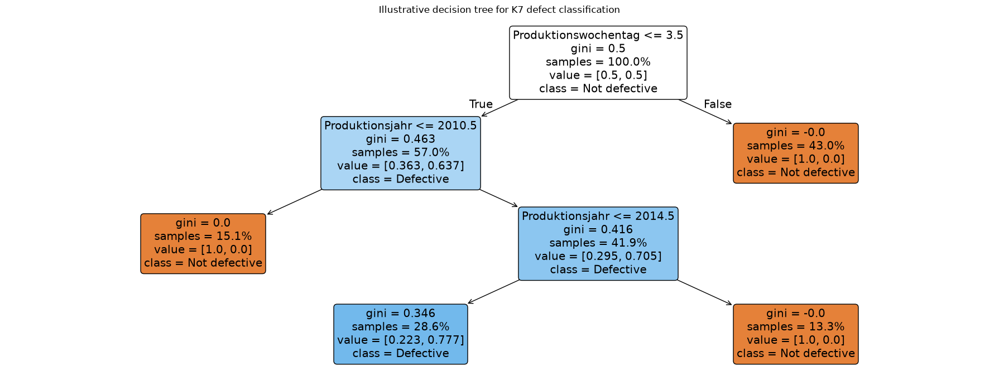

In [14]:
# Visualize the fitted decision rules.
plt.figure(figsize=(18, 7))
plot_tree(
    tree_model,
    feature_names=tree_features,
    class_names=["Not defective", "Defective"],
    filled=True,
    rounded=True,
    proportion=True,
    precision=3,
)
plt.title("Illustrative decision tree for K7 defect classification")
plt.tight_layout()
plt.show()

### Interpretation for (d)

The data contain only **6 defective parts out of 306,490**. This extreme imbalance is the dominant modeling issue. A class-weighted tree can be forced to pay attention to the defective class, but with so few positive examples it produces many false positives and its splits are unstable.

Therefore, the main conclusion is methodological: visualize the imbalance first, use stratified validation and imbalance-aware metrics, keep the tree interpretable, and **do not deploy this particular fitted tree as a reliable defect classifier without substantially more defective examples or additional predictive process/quality variables**.

## Final answers — Exercise 1

- **(a)** The logistics delay is best approximated by a **lognormal distribution** among the tested candidates. It has the best rounded-data AIC / chi-square discrepancy, but the exact-fit null is rejected in this very large rounded dataset, so the lognormal should be treated as a practical approximation rather than an exact law.
- **(b)** Mean logistics delay: **approximately 4.34 working days** (Monday-Friday, no public-holiday adjustment). Median and high percentiles are useful alternatives depending on the planning objective.
- **(c)** The Plotly histogram uses **1-day bins**. The raw Freedman-Diaconis width is much smaller than one day due to the huge sample, so it is capped at the actual one-day measurement resolution. The fitted lognormal density is overlaid.
- **(d)** A decision tree should be built after visualizing class imbalance, with interpretable predictors, stratified validation, class weighting, restricted complexity, a confusion matrix and imbalance-aware metrics. Here, only 6 positive cases exist, so the demonstration tree is not reliable enough for production use.

<a id="task2"></a>
# Exercise 2

It makes sense to store the available data in separate tables/files rather than combining everything into one large table. This corresponds to a typical relational database structure.

At least four important benefits are:
1. Less data redundancy: Information that belongs to one entity, such as a component or vehicle, does not have to be repeated in every row of one huge table.
2. Lower storage requirements: Avoiding repeated values reduces the amount of data that needs to be stored.
3. Better data consistency: If information changes, it only needs to be updated in one place. This reduces the risk of contradictory or outdated values.
4. Easier maintenance: Individual tables can be updated, extended, or corrected independently.
5. Clearer data organization: Different types of information, for example logistics, components, vehicles, and registrations, remain logically separated.
6. More efficient queries: Relevant tables can be joined only when required, instead of processing one unnecessarily large dataset every time.

The tables are connected through common identifiers or keys, such as component, vehicle, or registration IDs. This structure is called a relational database or relational database model

<a id="task3"></a>
# Exercise 3

In [15]:
# Exercise 3 – T16 parts in vehicles registered in Adelshofen

# 1. Load only the registration columns required

file_path_zulassung = (
    DATA_DIR
    / "raw"
    / "IDA SoSe26 - Data"
    / "Zulassungen"
    / "Zulassungen_alle_Fahrzeuge.csv"
)

zulassungen = pd.read_csv(
    file_path_zulassung,
    sep=";",
    usecols=["IDNummer", "Gemeinden"],
    dtype="string"
)


# 2. Select vehicles registered in Adelshofen

adelshofen_ids = zulassungen.loc[
    zulassungen["Gemeinden"]
    .str.strip()
    .str.upper()
    .eq("ADELSHOFEN"),
    "IDNummer"
]

print(f"Vehicles registered in Adelshofen: {len(adelshofen_ids)}")

# 3. Combine vehicle-component tables

bestandteile_dir = DATA_DIR / "raw" / "IDA SoSe26 - Data" / "Fahrzeug"

vehicle_files = [
    "Bestandteile_Fahrzeuge_OEM1_Typ11.csv",
    "Bestandteile_Fahrzeuge_OEM1_Typ12.csv",
    "Bestandteile_Fahrzeuge_OEM2_Typ21.csv",
    "Bestandteile_Fahrzeuge_OEM2_Typ22.csv",
]

component_columns = [
    "ID_Karosserie",
    "ID_Schaltung",
    "ID_Sitze",
    "ID_Motor",
]

vehicle_components = pd.concat(
    [
        pd.read_csv(
            bestandteile_dir / file,
            sep=";",
            usecols=["ID_Fahrzeug"] + component_columns,
            dtype="string"
        )
        for file in vehicle_files
    ],
    ignore_index=True
)

# 4. Keep only components belonging to Adelshofen vehicles

adelshofen_components = vehicle_components.loc[
    vehicle_components["ID_Fahrzeug"].isin(adelshofen_ids),
    component_columns
]

# 5. Determine how often each component type occurs

component_type_counts = (
    adelshofen_components
    .stack()
    .str.split("-", n=1)
    .str[0]
    .value_counts()
)

display(component_type_counts.to_frame("Count"))



# 6. Count components containing a T16 part
#
# Previous inspection of the component tables shows that
# T16 occurs in component types K2ST2 and K2LE2.

t16_parent_types = ["K2ST2", "K2LE2"]

total_t16 = component_type_counts.reindex(
    t16_parent_types,
    fill_value=0
).sum()

print(
    f"Number of T16 parts in vehicles registered "
    f"in Adelshofen: {total_t16}"
)

Vehicles registered in Adelshofen: 132


,Count
K4,70
K2ST1,70
K3SG1,63
K1BE1,44
K1DI1,40
K3SG2,40
K6,38
K2ST2,36
K1DI2,26
K1BE2,22


Number of T16 parts in vehicles registered in Adelshofen: 48


<a id="task4"></a>
# Exercise 4

In [16]:
# Display the first rows of the registration table
display(zulassungen.head())

# Show the pandas data type of every attribute
zulassungen.dtypes

,IDNummer,Gemeinden
0,11-1-11-1,DRESDEN
1,11-1-11-2,DRESDEN
2,12-1-12-1,LEIPZIG
3,12-1-12-2,LEIPZIG
4,12-1-12-3,DORTMUND


IDNummer     string
Gemeinden    string
dtype: object

### Exercise 4 – Data Types of the Registration Table

The registration table `Zulassungen_aller_Fahrzeuge` contains four attributes. Their pandas data types and their semantic interpretation are shown below.

| Attribute    | Pandas data type | Semantic data type               | Characteristics                                                                                                                                                                                                                                  |
| ------------ | ---------------- | -------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------ |
| `Unnamed: 0` | `int64`          | Integer / index                  | Contains whole numbers and appears to be an automatically stored row index. It does not represent an actual characteristic of a vehicle and can usually be removed from the analysis.                                                            |
| `IDNummer`   | `object`         | Nominal categorical / identifier | Contains alphanumeric vehicle identifiers such as `11-1-11-1`. Although pandas stores the values as `object`, they are identifiers rather than numerical measurements. Arithmetic operations or numerical ordering are therefore not meaningful. |
| `Gemeinden`  | `object`         | Nominal categorical              | Contains municipality or city names such as `DRESDEN`, `LEIPZIG`, or `DORTMUND`. The values represent categories without a natural order.                                                                                                        |
| `Zulassung`  | `object`         | Date / temporal variable         | Contains registration dates such as `2009-01-01`. Pandas currently stores the values as `object`, but semantically they represent dates and should preferably be converted to the `datetime64` data type for further analysis.                   |

The pandas data type alone does not always describe the actual meaning of a variable. In particular, both `IDNummer` and `Gemeinden` are stored as `object`, but they represent nominal categorical information. `Zulassung` is also currently stored as `object`, although its values represent dates.

For further analysis, the registration date should therefore be converted to a proper datetime variable:

```python
zulassungen["Zulassung"] = pd.to_datetime(zulassungen["Zulassung"])
```

After the conversion, the column has the pandas data type `datetime64[ns]`. This makes it possible to perform chronological sorting, calculate time differences, or extract components such as year, month, and weekday.

The column `Unnamed: 0` most likely originates from saving a previous DataFrame index to the CSV file. Since it does not contain meaningful information about the vehicles or registrations, it can normally be removed:

```python
zulassungen = zulassungen.drop(columns=["Unnamed: 0"])
```


<a id="task5"></a>
# Exercise 5

In [17]:
file_path_fehleranalyse= component_dir = DATA_DIR / "raw" / "IDA SoSe26 - Data" / "Fahrzeug"
fahrzeuge_oem1_typ11_fehleranalyse = pd.read_csv(
    bestandteile_dir / "Fahrzeuge_OEM1_Typ11_Fehleranalyse.csv"
)
# Create a shorter working name
df = fahrzeuge_oem1_typ11_fehleranalyse.copy()

# Inspect the dataset
display(df.head())

print("Shape:", df.shape)

print("\nData types:")
display(df.dtypes)

print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False))


# 1. Define target variable

# Fehlerhaft_Fahrleistung represents the mileage at which
# the recorded fault occurred.
TARGET = "Fehlerhaft_Fahrleistung"


# 2. Check correlations of numeric variables with mileage
numeric_df = df.select_dtypes(include="number")

correlations = (
    numeric_df.corr()[TARGET]
    .drop(TARGET)
    .sort_values(key=abs, ascending=False)
)

display(correlations.to_frame("Correlation with mileage"))

,Unnamed: 0,X,X1,ID_Fahrzeug,Herstellernummer,Werksnummer,Fehlerhaft_Datum,Fehlerhaft_Fahrleistung,days,fuel,engine
0,9,9,9,11-1-11-9,1,11,2010-03-16,"34,824.3196","1,493.1508",4.0037,small
1,11,11,11,11-1-11-11,1,11,2010-03-16,"74,217.4283","1,044.4622",11.0425,large
2,13,13,13,11-1-11-13,1,11,2010-03-16,"32,230.6996",749.6698,3.5791,small
3,15,15,15,11-1-11-15,1,11,2010-03-16,"44,885.7836",858.6880,4.6668,small
4,37,37,37,11-1-11-37,1,11,2010-03-17,"86,348.3299","1,478.2042",4.6344,small


Shape: (198069, 11)

Data types:


Unnamed: 0                   int64
X                            int64
X1                           int64
ID_Fahrzeug                    str
Herstellernummer             int64
Werksnummer                  int64
Fehlerhaft_Datum               str
Fehlerhaft_Fahrleistung    float64
days                       float64
fuel                       float64
engine                         str
dtype: object


Missing values:


Unnamed: 0                 0
X                          0
X1                         0
ID_Fahrzeug                0
Herstellernummer           0
Werksnummer                0
Fehlerhaft_Datum           0
Fehlerhaft_Fahrleistung    0
days                       0
fuel                       0
engine                     0
dtype: int64

,Correlation with mileage
fuel,0.6896
Unnamed: 0,-0.0033
X,-0.0033
X1,-0.0033
days,0.0017
Werksnummer,0.0011
Herstellernummer,NaN


### Selection of explanatory variables

The target variable is `Fehlerhaft_Fahrleistung`, which represents the mileage
at which a fault was recorded.

The columns `Unnamed: 0`, `X` and `X1` are index-like variables and are therefore
not meaningful explanatory variables. `ID_Fahrzeug` is an identifier, while
`Herstellernummer` and `Werksnummer` are database identifiers rather than
continuous vehicle characteristics.

The variables `fuel` and `engine` are therefore used as explanatory variables.
Although `engine` has the data type `object`, it is a categorical variable and
can be included in a linear regression after one-hot encoding.

The variable `days` was initially considered as an additional predictor, but its
correlation with mileage is close to zero and it provides almost no additional
explanatory power.

In [18]:
# 3. Visualize mileage by engine category

fig = px.box(
    df,
    x="engine",
    y=TARGET,
    title="Mileage by engine category",
    labels={
        "engine": "Engine category",
        TARGET: "Mileage"
    }
)

fig.show()

In [19]:
# Calculate descriptive statistics for the engine categories

engine_summary = (
    df.groupby("engine")
    .agg(
        observations=(TARGET, "count"),
        mean_mileage=(TARGET, "mean"),
        mean_fuel=("fuel", "mean")
    )
    .round(2)
)

display(engine_summary)

,observations,mean_mileage,mean_fuel
engine,,,
large,7318,"72,082.5300",11.9500
medium,23053,"60,136.1400",8.1700
small,167698,"41,364.6800",3.9500


In [20]:
# 4. Prepare the variables for the linear regression

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

import numpy as np


# Explanatory variables
# fuel is numerical
# engine is categorical
X = df[["fuel", "engine"]]

# Target variable: mileage
y = df[TARGET]


# Split the data into training and test datasets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [21]:
# 5. Convert the categorical engine variable

# Linear regression requires numerical input.
# OneHotEncoder converts the engine categories into dummy variables.
#
# drop="first" uses one engine category as the reference category
# and prevents redundant dummy variables.

preprocessor = ColumnTransformer(
    transformers=[
        (
            "engine",
            OneHotEncoder(drop="first", handle_unknown="ignore"),
            ["engine"]
        )
    ],
    remainder="passthrough"
)

In [22]:
# 6. Create and train the linear regression model

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regression", LinearRegression())
])

model.fit(X_train, y_train)

# Predict mileage for the test dataset
y_pred = model.predict(X_test)

In [23]:
# 7. Evaluate the model

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R²:   {r2:.3f}")
print(f"MAE:  {mae:,.0f} km")
print(f"RMSE: {rmse:,.0f} km")

R²:   0.490
MAE:  8,707 km
RMSE: 11,114 km


In [24]:
# 8. Display the regression coefficients

feature_names = (
    model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

coefficients = (
    model
    .named_steps["regression"]
    .coef_
)

coefficient_table = pd.DataFrame({
    "Variable": feature_names,
    "Coefficient": coefficients
})

# Clean up sklearn's prefixes
coefficient_table["Variable"] = (
    coefficient_table["Variable"]
    .str.replace("engine__", "", regex=False)
    .str.replace("remainder__", "", regex=False)
)

display(coefficient_table)

print(
    "Intercept:",
    round(model.named_steps["regression"].intercept_, 2)
)

,Variable,Coefficient
0,engine_medium,"7,705.4069"
1,engine_small,"10,953.9689"
2,fuel,"5,213.5951"


Intercept: 9804.53


In [25]:
# 9. Compare actual and predicted mileage

results = pd.DataFrame({
    "Actual mileage": y_test,
    "Predicted mileage": y_pred
})

fig = px.scatter(
    results,
    x="Actual mileage",
    y="Predicted mileage",
    title="Actual vs. predicted mileage"
)

# Add a diagonal reference line.
# Points close to this line were predicted accurately.

minimum = min(
    results["Actual mileage"].min(),
    results["Predicted mileage"].min()
)

maximum = max(
    results["Actual mileage"].max(),
    results["Predicted mileage"].max()
)

fig.add_shape(
    type="line",
    x0=minimum,
    y0=minimum,
    x1=maximum,
    y1=maximum,
    line=dict(dash="dash")
)

fig.show()

### Interpretation and recommendation for OEM1

A multiple linear regression was created to explain the mileage at which a fault
was recorded (`Fehlerhaft_Fahrleistung`). Fuel consumption (`fuel`) and engine
category (`engine`) were selected as explanatory variables.

The engine variable is categorical and was therefore transformed into dummy
variables using one-hot encoding. Identifier and index variables were excluded
because their numerical values have no meaningful quantitative interpretation
for vehicle mileage.

The model achieves an R² of approximately 0.49. This means that around 49% of
the variation in the recorded mileage can be explained by fuel consumption and
engine category. The mean absolute prediction error is approximately 8,700 km.

Fuel consumption has a strong relationship with mileage. Engine category also
provides additional explanatory information. The descriptive analysis shows
that vehicles with different engine categories have substantially different
average mileage values and fuel consumption.

For OEM1, the results suggest that engine configuration and fuel consumption
should be considered when analysing component durability and expected failure
mileage. Vehicle groups with different engine configurations could therefore be
assigned different inspection, maintenance or component replacement strategies.

However, the relationship should not be interpreted as causal. In particular,
higher fuel consumption does not necessarily cause higher mileage. Fuel
consumption is strongly related to engine configuration and may therefore also
represent differences in vehicle design, intended use or component durability.
Further technical analysis would be necessary before making engineering changes.

<a id="task6"></a>
# Exercise 6


In [26]:
# Path to the vehicle-component table
file_path_bestandteile = DATA_DIR / "raw" / "IDA SoSe26 - Data" / "Fahrzeug" / "Bestandteile_Fahrzeuge_OEM1_Typ12.csv"

# Load the CSV file
bestandteile_typ12 = pd.read_csv(file_path_bestandteile, sep=";")

# Body part number from the hit-and-run vehicle
gesuchte_karosserie = "K5-112-1122-79"

# Find the vehicle that contains this body part
fahrzeug_treffer = bestandteile_typ12[
    bestandteile_typ12["ID_Karosserie"] == gesuchte_karosserie
]

display(fahrzeug_treffer)

# Extract the vehicle ID
id_fahrzeug = fahrzeug_treffer["ID_Fahrzeug"].iloc[0]

print("ID_Fahrzeug:", id_fahrzeug)

# Find this vehicle in the registration table
zulassungs_treffer = zulassungen[
    zulassungen["IDNummer"] == id_fahrzeug
]

display(zulassungs_treffer)

# Extract the municipality
gemeinde = zulassungs_treffer["Gemeinden"].iloc[0]

print("Das Fahrzeug wurde registriert in:", gemeinde)


,Unnamed: 0,ID_Karosserie,ID_Schaltung,ID_Sitze,ID_Motor,ID_Fahrzeug
81,82,K5-112-1122-79,K3SG1-105-1051-129,K2ST1-109-1092-519,K1BE1-104-1041-409,12-1-12-82


ID_Fahrzeug: 12-1-12-82


,IDNummer,Gemeinden
223,12-1-12-82,ASCHERSLEBEN


Das Fahrzeug wurde registriert in: ASCHERSLEBEN
